In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.seasonal import STL

from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().resolve().parent))
print(sys.executable)

from src.metrics import *
print("ok")

/Users/yuanxinyi/Desktop/panel-forcast-kit/.venv/bin/python
ok


In [3]:
project_root = Path.cwd().resolve().parent if "panel-forcast-kit" in str(Path.cwd()) else Path.cwd()

processed_dir = project_root / "data" / "processed"

X_train = pd.read_csv(processed_dir / "X_train.csv")
y_train = pd.read_csv(processed_dir / "y_train.csv")
X_test = pd.read_csv(processed_dir / "X_test.csv")
y_test = pd.read_csv(processed_dir / "y_test.csv")

# 统一为 Series / DataFrame 的形式
X_train = X_train.copy()
y_train = y_train.iloc[:, 0].copy()
X_test = X_test.copy()
y_test = y_test.iloc[:, 0].copy()

print("Loaded:")
print(f"X_train shape: {X_train.shape}, \n{X_train.head(1)}")
print(f"\ny_train shape: {y_train.shape}, \n{y_train.head(1)}")
print(f"\nX_test shape: {X_test.shape}, \n{X_test.head(1)}")
print(f"\ny_test shape: {y_test.shape}, \n{y_test.head(1)}")

Loaded:
X_train shape: (853000, 11), 
   store  item  day  month  is_weekend  is_holiday  lag_1  lag_7  lag_14  \
0      1     1   29      1           0           0   11.0    7.0     5.0   

   lag_28  rolling_mean_7  
0    13.0       10.428571  

y_train shape: (853000,), 
0    6
Name: sales, dtype: int64

X_test shape: (46000, 11), 
   store  item  day  month  is_weekend  is_holiday  lag_1  lag_7  lag_14  \
0      1     1    1     10           1           0   30.0   24.0    30.0   

   lag_28  rolling_mean_7  
0    23.0       23.428571  

y_test shape: (46000,), 
0    21
Name: sales, dtype: int64


# Multi-window Backtest: XGB vs XGB + Linear

In [ ]:
# test
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import pandas as pd
import numpy as np
from xgboost import XGBRegressor

num_cols = ["lag_1", "lag_7", "lag_14", "lag_28", "rolling_mean_7"]

tscv = TimeSeriesSplit(n_splits=5)
results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    X_tr = X_train.iloc[train_idx].copy()
    y_tr = y_train.iloc[train_idx].copy()
    X_val = X_train.iloc[val_idx].copy()
    y_val = y_train.iloc[val_idx].copy()

    # XGB
    xgb = XGBRegressor(
        objective="count:poisson",
        eval_metric="poisson-nloglik",
        learning_rate=0.05,
        n_estimators=600,
        max_depth=8,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )
    xgb.fit(X_tr, y_tr)
    xgb_pred = xgb.predict(X_val)
    xgb_mae, xgb_rmse, xgb_wape = evaluate(y_val, xgb_pred)

    # Ridge as linear trend reference
    X_tr_scaled = X_tr.copy()
    X_val_scaled = X_val.copy()
    scaler = StandardScaler()
    X_tr_scaled[num_cols] = scaler.fit_transform(X_tr[num_cols])
    X_val_scaled[num_cols] = scaler.transform(X_val[num_cols])

    ridge = Ridge(alpha=1.0)
    ridge.fit(X_tr_scaled, y_tr)
    ridge_pred = ridge.predict(X_val_scaled)

    # ensemble: XGB + linear, with a conservative weight
    ensemble_pred = 0.8 * xgb_pred + 0.2 * ridge_pred
    ens_mae, ens_rmse, ens_wape = evaluate(y_val, ensemble_pred)

    results.append({
        "fold": fold,
        "XGB_MAE": xgb_mae,
        "XGB_RMSE": xgb_rmse,
        "XGB_WAPE": xgb_wape,
        "XGBLinear_MAE": ens_mae,
        "XGBLinear_RMSE": ens_rmse,
        "XGBLinear_WAPE": ens_wape,
    })

results_df = pd.DataFrame(results)
print("=== Multi-window benchmark: XGB vs XGB + Linear ===")
print(results_df.to_string(index=False))
print("\nAverage metrics:")
print(results_df.mean(numeric_only=True).round(4).to_string())

xgb_wins = (results_df["XGB_WAPE"] < results_df["XGBLinear_WAPE"]).sum()
linear_wins = (results_df["XGB_WAPE"] >= results_df["XGBLinear_WAPE"]).sum()

print(f"\nXGB wins by WAPE: {xgb_wins} / {len(results_df)} folds")
print(f"XGB + Linear wins by WAPE: {linear_wins} / {len(results_df)} folds")

=== Multi-window benchmark: XGB vs XGB + Linear ===
 fold  XGB_MAE  XGB_RMSE  XGB_WAPE  XGBLinear_MAE  XGBLinear_RMSE  XGBLinear_WAPE
    1 6.542175  8.467073  0.110070       6.558894        8.485644        0.110351
    2 5.755415  7.428890  0.125782       5.762340        7.445169        0.125934
    3 5.259732  6.797298  0.134050       5.274224        6.817017        0.134419
    4 6.802442  9.087328  0.120139       6.652208        8.834872        0.117485
    5 6.377826  8.246276  0.111410       6.405697        8.281071        0.111897

Average metrics:
fold              3.0000
XGB_MAE           6.1475
XGB_RMSE          8.0054
XGB_WAPE          0.1203
XGBLinear_MAE     6.1307
XGBLinear_RMSE    7.9728
XGBLinear_WAPE    0.1200

XGB wins by WAPE: 4 / 5 folds
XGB + Linear wins by WAPE: 1 / 5 folds


In [ ]:
# True rolling time-window backtest
# Reslice training/validation windows at each step and compare the performance of XGB vs. XGB+linear
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from xgboost import XGBRegressor
import pandas as pd
import numpy as np

num_cols = ["lag_1", "lag_7", "lag_14", "lag_28", "rolling_mean_7"]

n_total = len(X_train)
train_size = int(n_total * 0.6)   # Training window length
val_size = int(n_total * 0.1)     # Validation window length
step = int(n_total * 0.1)         # Rolling step size per iteration

records = []

for start in range(train_size, n_total - val_size + 1, step):
    train_end = start
    val_end = start + val_size

    X_tr = X_train.iloc[:train_end].copy()
    y_tr = y_train.iloc[:train_end].copy()
    X_val = X_train.iloc[train_end:val_end].copy()
    y_val = y_train.iloc[train_end:val_end].copy()

    # ---- XGB ----
    xgb = XGBRegressor(
        objective="count:poisson",
        eval_metric="poisson-nloglik",
        learning_rate=0.05,
        n_estimators=600,
        max_depth=8,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )
    xgb.fit(X_tr, y_tr)
    xgb_pred = xgb.predict(X_val)

    # ---- Linear reference models ----
    X_tr_scaled = X_tr.copy()
    X_val_scaled = X_val.copy()
    scaler = StandardScaler()
    X_tr_scaled[num_cols] = scaler.fit_transform(X_tr[num_cols])
    X_val_scaled[num_cols] = scaler.transform(X_val[num_cols])

    ridge = Ridge(alpha=1.0)
    ridge.fit(X_tr_scaled, y_tr)
    ridge_pred = ridge.predict(X_val_scaled)

    enet = ElasticNet(alpha=0.026, l1_ratio=1, max_iter=20000)
    enet.fit(X_tr_scaled, y_tr)
    enet_pred = enet.predict(X_val_scaled)

    # ---- Ensemble predictions ----
    ensemble_defs = {
        "XGB": lambda px, pr, pe: px,
        "XGB + Ridge (0.8/0.2)": lambda px, pr, pe: 0.8 * px + 0.2 * pr,
        "XGB + ElasticNet (0.8/0.2)": lambda px, pr, pe: 0.8 * px + 0.2 * pe,
        "XGB + Ridge + ElasticNet (0.7/0.15/0.15)": lambda px, pr, pe: 0.7 * px + 0.15 * pr + 0.15 * pe,
    }

    for name, pred_fn in ensemble_defs.items():
        pred = pred_fn(xgb_pred, ridge_pred, enet_pred)
        mae, rmse, wape = evaluate(y_val, pred)
        records.append({
            "train_end": train_end,
            "val_end": val_end,
            "model": name,
            "MAE": mae,
            "RMSE": rmse,
            "WAPE": wape
        })

summary = pd.DataFrame(records)
print("=== Rolling-window benchmark ===")
print(summary.to_string(index=False))

avg_summary = summary.groupby("model")[["MAE", "RMSE", "WAPE"]].mean().sort_values("WAPE")
print("\n=== Average by model ===")
print(avg_summary.round(4).to_string())

best_by_window = []
for win in sorted(summary["train_end"].unique()):
    sub = summary[summary["train_end"] == win]
    best_model = sub.loc[sub["WAPE"].idxmin(), "model"]
    best_by_window.append({"train_end": win, "best_model": best_model})

best_df = pd.DataFrame(best_by_window)
print("\n=== Best model by window ===")
print(best_df.to_string(index=False))
print("\nWin counts:")
print(best_df["best_model"].value_counts().to_string())

=== Rolling-window benchmark ===
 train_end  val_end                                    model      MAE     RMSE     WAPE
    511800   597100                                      XGB 5.078792 6.559538 0.139021
    511800   597100                    XGB + Ridge (0.8/0.2) 5.091862 6.577336 0.139379
    511800   597100               XGB + ElasticNet (0.8/0.2) 5.091914 6.577252 0.139380
    511800   597100 XGB + Ridge + ElasticNet (0.7/0.15/0.15) 5.109489 6.599974 0.139861
    597100   682400                                      XGB 7.458770 9.905101 0.115770
    597100   682400                    XGB + Ridge (0.8/0.2) 7.247462 9.569339 0.112491
    597100   682400               XGB + ElasticNet (0.8/0.2) 7.248289 9.570903 0.112503
    597100   682400 XGB + Ridge + ElasticNet (0.7/0.15/0.15) 7.181903 9.455271 0.111473
    682400   767700                                      XGB 6.287314 8.127786 0.113686
    682400   767700                    XGB + Ridge (0.8/0.2) 6.309084 8.157056 0.114079

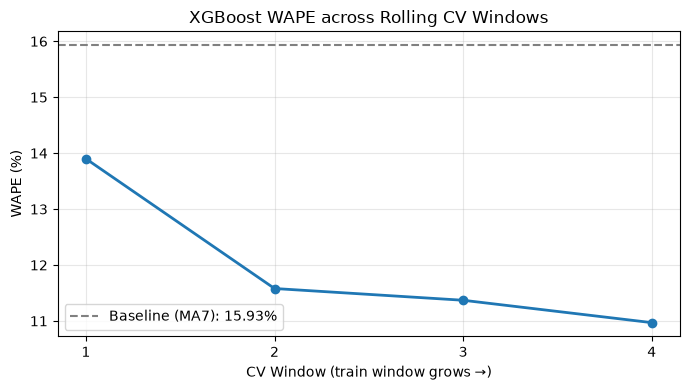

In [11]:
import matplotlib.pyplot as plt
import os

os.makedirs("../assets", exist_ok=True)   

windows = [1, 2, 3, 4]
wape = [13.90, 11.58, 11.37, 10.97]      

plt.figure(figsize=(7, 4))
plt.plot(windows, wape, marker="o", linewidth=2)
plt.axhline(15.93, color="gray", linestyle="--", label="Baseline (MA7): 15.93%")
plt.title("XGBoost WAPE across Rolling CV Windows")
plt.xlabel("CV Window (train window grows →)")
plt.ylabel("WAPE (%)")
plt.xticks(windows)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../assets/cv_wape.png", dpi=150, bbox_inches="tight")
plt.show()

# Error Analysis

In [8]:
import pandas as pd
import numpy as np

# 1) Use the final fitted XGB model to predict the test set
feature_cols = X_train.columns.tolist()

xgb = XGBRegressor(
    objective="count:poisson",
    eval_metric="poisson-nloglik",
    learning_rate=0.05,
    n_estimators=600,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train, y_train)

eval_df = X_test.copy()
eval_df["sales"] = y_test.to_numpy()
eval_df["pred"] = xgb.predict(X_test[feature_cols])
eval_df["abs_err"] = (eval_df["sales"] - eval_df["pred"]).abs()

# 2) Aggregate by item: absolute error vs relative error
item_err = (
    eval_df.groupby("item", as_index=False)
    .agg(
        avg_sales=("sales", "mean"),
        mae=("abs_err", "mean"),
        total_sales=("sales", "sum"),
        total_abs_err=("abs_err", "sum"),
    )
)
item_err["wape"] = item_err["total_abs_err"] / item_err["total_sales"]

print("=== Top 10 items by MAE ===")
print(item_err.sort_values("mae", ascending=False)[["item", "avg_sales", "mae", "wape"]].head(10).round(3))

print("\n=== Top 10 items by WAPE (least accurate) ===")
print(item_err.sort_values("wape", ascending=False)[["item", "avg_sales", "mae", "wape"]].head(10).round(3))

print("\n=== Top 10 items by WAPE (most accurate) ===")
print(item_err.sort_values("wape")[["item", "avg_sales", "mae", "wape"]].head(10).round(3))

# 3) Aggregate by store
store_err = (
    eval_df.groupby("store", as_index=False)
    .agg(
        total_sales=("sales", "sum"),
        total_abs_err=("abs_err", "sum")
    )
)
store_err["wape"] = store_err["total_abs_err"] / store_err["total_sales"]

print("\n=== Store-level WAPE (worst to best) ===")
print(store_err.sort_values("wape", ascending=False)[["store", "wape"]].round(4))

=== Top 10 items by MAE ===
    item  avg_sales    mae   wape
37    38     84.897  8.476  0.100
27    28     92.133  8.417  0.091
12    13     88.002  8.401  0.095
14    15     92.303  8.304  0.090
24    25     84.214  8.249  0.098
17    18     88.132  8.232  0.093
44    45     84.077  8.132  0.097
7      8     80.997  8.126  0.100
21    22     84.265  7.944  0.094
28    29     72.755  7.905  0.109

=== Top 10 items by WAPE (least accurate) ===
    item  avg_sales    mae   wape
4      5     19.317  3.742  0.194
40    41     22.789  4.188  0.184
46    47     22.970  4.034  0.176
3      4     22.970  4.020  0.175
26    27     22.792  3.966  0.174
0      1     22.940  3.955  0.172
22    23     30.813  5.107  0.166
15    16     26.600  4.356  0.164
33    34     27.058  4.345  0.161
39    40     30.745  4.861  0.158

=== Top 10 items by WAPE (most accurate) ===
    item  avg_sales    mae   wape
14    15     92.303  8.304  0.090
27    28     92.133  8.417  0.091
17    18     88.132  8.232  0